MD# 04 · Logistic regression scorecard

**Northvale Credit is a fictional lender; the data is public Lending Club loans.**

Question: how far does a transparent, points-based scorecard get compared with Lending Club's own sub-grade? Steps (in `src/northvale/models.py`): optimal monotonic binning with weight of evidence (optbinning), IV filter, correlation filter, stepwise selection on validation AUC with a coefficient sign check, logistic regression, points scaling (600 points at 50:1 good:bad odds, 20 points to double the odds), Platt recalibration on January-June 2015.

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, display

from northvale import config as C

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 20)
m = json.loads(C.METRICS.read_text())


def fig(name, width=900):
    display(Image(filename=str(C.FIGURES / f"{name}.png"), width=width))

MD## 1. Selection log

Characteristics in order of information value (IV), with the step that kept or removed each.

In [2]:
sel = pd.read_csv(C.TABLES / "scorecard_selection.csv")
sel.head(25)

,characteristic,iv,step
0,fico,0.1361,added (validation AUC 0.5987)
1,annual_inc,0.0890,added (validation AUC 0.6132)
2,bc_open_to_buy,0.0833,added (validation AUC 0.6150)
3,tot_hi_cred_lim,0.0741,added (validation AUC 0.6171)
4,total_bc_limit,0.0729,dropped: |r| > 0.7 with bc_open_to_buy
5,avg_cur_bal,0.0686,dropped: |r| > 0.7 with tot_hi_cred_lim
6,tot_cur_bal,0.0598,dropped: |r| > 0.7 with tot_hi_cred_lim
7,acc_open_past_24mths,0.0558,added (validation AUC 0.6479)
8,total_rev_hi_lim,0.0543,not added: would flip a coefficient sign
9,dti,0.0487,added (validation AUC 0.6538)


MD## 2. Points table (two characteristics shown)

With WoE defined as ln(share of goods / share of bads), every coefficient must be negative: a safer bin (higher WoE) must lower the predicted default risk and add points.

In [3]:
pts = pd.read_csv(C.TABLES / "scorecard_points.csv")
print("coefficients all negative:", bool((pts.groupby("characteristic")["coefficient"].first() < 0).all()))
pts[pts["characteristic"].isin(["fico", "dti"])][["characteristic", "bin", "count", "event_rate", "woe", "points"]]

coefficients all negative: True


,characteristic,bin,count,event_rate,woe,points
0,fico,"(-inf, 664.50)",27011,0.1854,-0.3992,35
1,fico,"[664.50, 669.50)",27151,0.1748,-0.3273,36
2,fico,"[669.50, 674.50)",27529,0.1705,-0.2971,37
3,fico,"[674.50, 679.50)",24798,0.1571,-0.1991,38
4,fico,"[679.50, 684.50)",24662,0.1546,-0.1801,39
5,fico,"[684.50, 689.50)",22025,0.1451,-0.1055,40
6,fico,"[689.50, 694.50)",21216,0.1322,0.0022,42
7,fico,"[694.50, 699.50)",19146,0.1285,0.0351,42
8,fico,"[699.50, 704.50)",17053,0.1173,0.1385,44
9,fico,"[704.50, 709.50)",15230,0.1100,0.2109,45


MD## 3. Test-window performance against the incumbent

In [4]:
cols = ["auc", "gini", "ks", "brier", "mean_pd", "observed", "psi_train_test"]
pd.DataFrame({k: {c: m["models"][k][c] for c in cols} for k in ("grade", "scorecard", "lgbm")})

,grade,scorecard,lgbm
auc,0.6814,0.6746,0.7008
gini,0.3628,0.3492,0.4017
ks,0.2665,0.2533,0.2918
brier,0.1189,0.1192,0.1171
mean_pd,0.1448,0.1450,0.1458
observed,0.1470,0.1470,0.1470
psi_train_test,0.0231,0.0044,0.0050


In [5]:
pd.read_csv(C.TABLES / "deciles_scorecard_test.csv")

,decile,n,default_rate,mean_pd
0,1,16200,0.0355,0.0400
1,2,16200,0.0694,0.0670
2,3,16199,0.0903,0.0871
3,4,16200,0.1041,0.1058
4,5,16200,0.1251,0.1240
5,6,16199,0.1451,0.1435
6,7,16200,0.1665,0.1651
7,8,16199,0.1922,0.1911
8,9,16200,0.2356,0.2264
9,10,16200,0.3068,0.3001


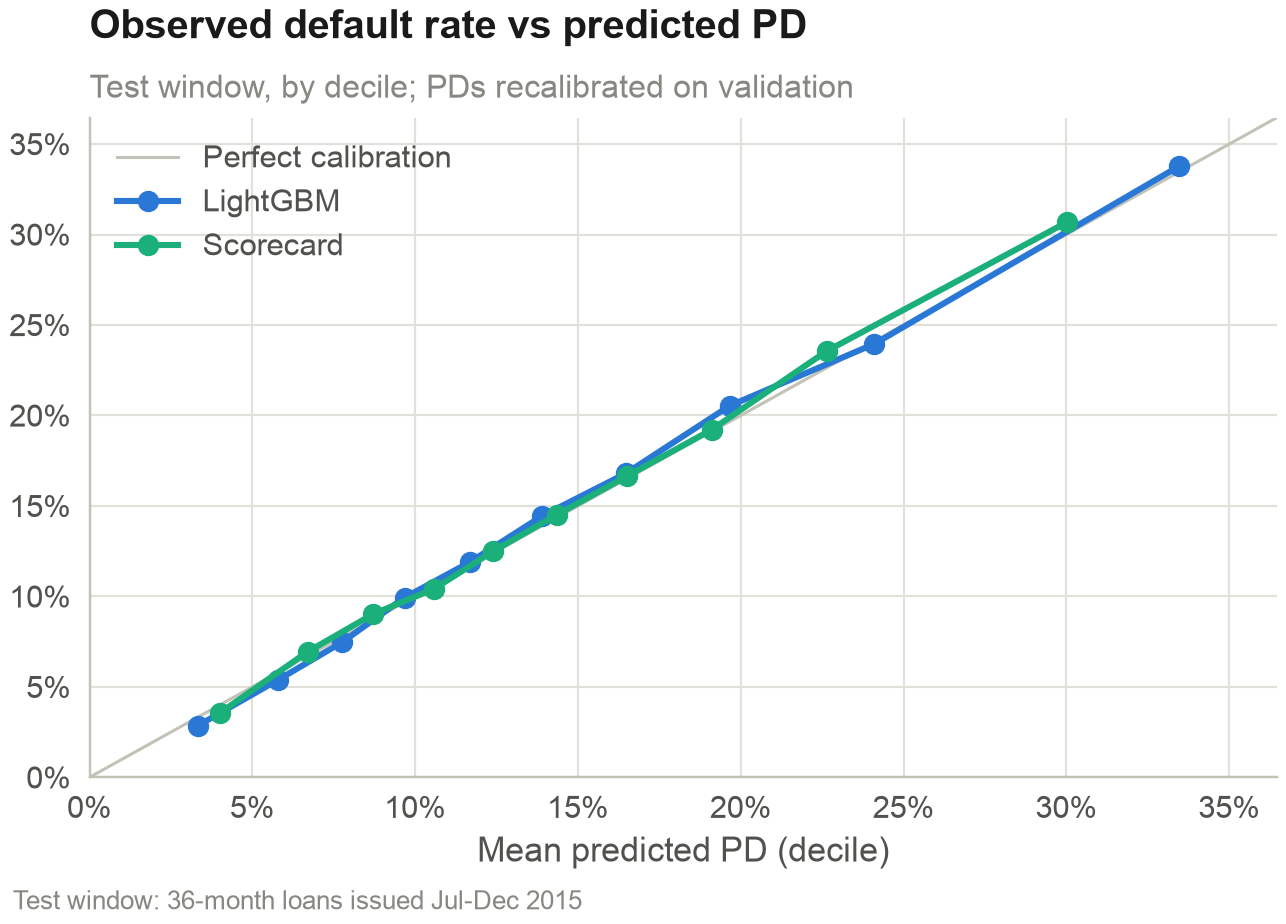

In [6]:
fig("calibration_test", 600)

MD**Answer.** The scorecard is well calibrated after recalibration and stable (PSI near zero), but on the 2015 H2 test window it ranks risk slightly worse than Lending Club's sub-grade. Its value is transparency: a short list of characteristics with monotonic points a credit officer can read. It is kept as the challenger and the fallback if a gradient-boosted model is not accepted.